# Capítulo 8 · Agradecimientos y práctica de cierre

**Lectura:** p. 199. [Apartado original](https://arxiv.org/html/2412.05265v5#Ch8).

## Resumen fiel al apartado

Este capítulo reconoce la procedencia de parte del material de los capítulos 34 y 35 de *Probabilistic Machine Learning: Advanced Topics*, incluyendo trabajo escrito con Lihong Li. Murphy indica que esta monografía amplía y sustituye aquel tratamiento. También agradece comentarios de colegas y ayuda con figuras.

No introduce algoritmos ni resultados técnicos. La bibliografía que sigue tampoco es un capítulo de métodos. Para acompañar todos los capítulos numerados sin inventar contenido, añadimos una práctica metodológica propia, conectada con §1.3.7.

## Experimento 8 · Elegir la mejor semilla fabrica una mejora

**Pregunta:** ¿qué sucede si comparamos la mejor ejecución de un algoritmo con el promedio de otro?

Simulamos 2.000 estudios. En cada uno, A y B tienen exactamente la misma distribución real de rendimiento, normal de media 0 y desviación 1, y disponemos de 20 semillas de cada algoritmo.

Comparamos tres formas de informar: media de A menos media de B; máximo de A menos media de B; y una nueva evaluación independiente del resultado seleccionado. En este modelo toda semilla comparte calidad real, así que seleccionar solo el ruido positivo no crea una mejora real.

~~~bash
uv run python -m experimentos.ejecutar --capitulo 8
~~~

**Hipótesis:** comparar todas las semillas produce una diferencia cercana a cero. Seleccionar la mejor de A produce una ventaja positiva ficticia.

**Métrica:** distribución de la ventaja observada en los estudios. El resultado guardado muestra aproximadamente 0.001 al comparar medias, 1.864 al seleccionar la mejor semilla y −0.044 en la evaluación independiente. Son fluctuaciones de la simulación alrededor de las expectativas correspondientes.

**Modificación:** cambia 20 semillas a 5 y a 100. Cuantas más oportunidades de seleccionar un extremo, mayor puede ser el optimismo introducido por esa selección.

**Límite:** aquí las diferencias entre semillas son puro ruido, por construcción. En una tarea real puede existir calidad persistente entre políticas; la evaluación independiente sigue siendo necesaria para distinguirla del ruido de selección.



## Para cerrar el grupo

Lleva una pequeña ficha con el entorno, la recompensa, la política, el presupuesto de interacción y cómputo, las semillas y las métricas. Añade una afirmación respaldada por tus datos y otra que tus datos no permiten sostener. Cita al autor del libro y distingue los experimentos de esta guía de las figuras o resultados originales.


## Preparar la ejecución

Ejecuta todas las celdas en orden. El módulo contiene la implementación completa; la siguiente celda muestra su código. Cambia SEMILLA y REPLICAS para repetir. Los resultados del cuaderno se guardan en una carpeta separada.

In [1]:
from pathlib import Path
import sys
import json
import inspect
import subprocess
import importlib
from IPython.display import display, Image, Code

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "experimentos" / "ejecutar.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
CAPITULO = 8
SEMILLA = 2026
REPLICAS = 20
SALIDA = ROOT / "resultados" / "cuadernos"
modulo = importlib.import_module(f"experimentos.cap{CAPITULO:02d}")
display(Code(inspect.getsource(modulo), language="python"))

"""Cierre metodológico añadido a los agradecimientos; no es un método del cap. 8."""
import numpy as np
import matplotlib.pyplot as plt
from .comun import guardar

def ejecutar(out, seed=2026, replicas=20):
    rng = np.random.default_rng(seed)
    # Dos algoritmos idénticos N(0,1). Cada estudio tiene 20 semillas por algoritmo.
    estudios = max(2000, replicas*100)
    a = rng.normal(size=(estudios, 20))
    b = rng.normal(size=(estudios, 20))
    honest = a.mean(axis=1)-b.mean(axis=1)
    selected = a.max(axis=1)-b.mean(axis=1)
    # Evaluación independiente del resultado elegido: no reutiliza su ruido.
    heldout = rng.normal(size=estudios)-rng.normal(size=(estudios, 20)).mean(axis=1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].hist(honest, bins=45, density=True, alpha=.6, label="Media A − media B")
    ax[0].hist(selected, bins=45, density=True, alpha=.6, label="Mejor semilla A − media B")
    ax[0].axvline(0, color="black", ls="--")
    ax[0].set(xlabel="Ventaja aparente", ylabel="Densidad", title="A y B tienen idéntico rendimiento real")
    ax[0].legend(fontsize=8)
    ax[1].bar(["Todas las\nsemillas", "Selección de\nla mejor", "Evaluación\nindependiente"],
              [honest.mean(), selected.mean(), heldout.mean()])
    ax[1].set(ylabel="Ventaja media observada", title="La selección fabrica una mejora")
    rows = [{"estudio": i, "diferencia_medias": float(honest[i]),
             "ventaja_seleccionada": float(selected[i]), "ventaja_independiente": float(heldout[i])}
            for i in range(estudios)]
    metrics = {"estudios": estudios, "semillas_por_algoritmo": 20,
               "diferencia_real": 0, "diferencia_media_observada": float(honest.mean()),
               "ventaja_seleccionando_mejor_semilla": float(selected.mean()),
               "ventaja_evaluacion_independiente": float(heldout.mean()),
               "nota": "Simulación estadística añadida por esta guía; vinculada a §1.3.7."}
    return guardar(out, dict(honest=honest, selected=selected, heldout=heldout), rows, metrics, fig)

## Ejecutar y registrar

El comando utiliza el mismo Python del kernel y conserva parámetros y hashes en su manifiesto. No necesita servicios externos.

In [2]:
command = [sys.executable, "-m", "experimentos.ejecutar",
           "--capitulo", str(CAPITULO), "--semilla", str(SEMILLA),
           "--replicas", str(REPLICAS), "--salida", str(SALIDA)]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, check=True)
print(completed.stdout)
carpeta = SALIDA / f"cap{CAPITULO:02d}"

Capítulo 8: completado en 0.20 s → /home/ialab/jairo_experiments/kevinMurphy/resultados/cuadernos/cap08



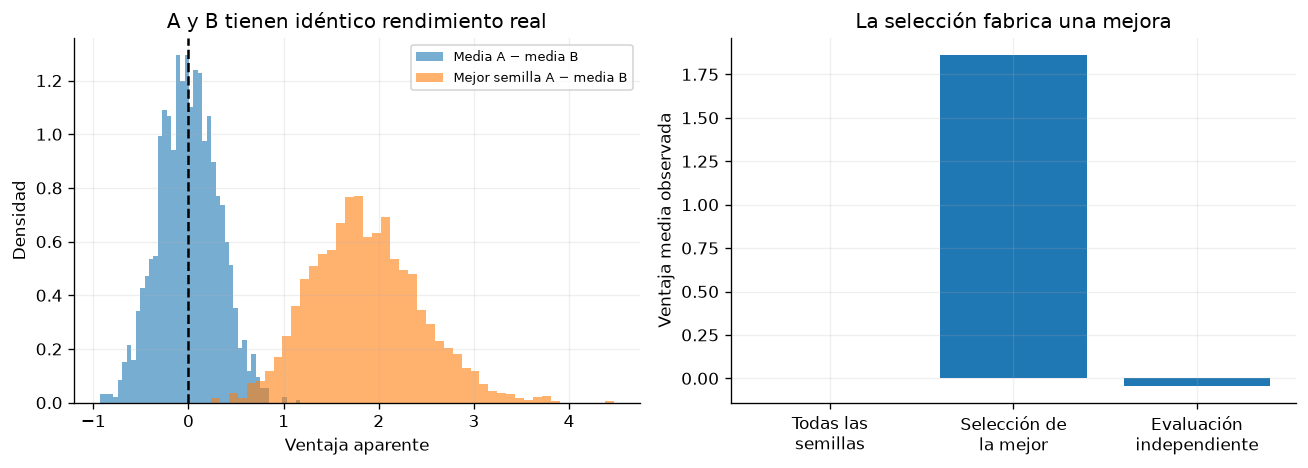

{
  "estudios": 2000,
  "semillas_por_algoritmo": 20,
  "diferencia_real": 0,
  "diferencia_media_observada": 0.0013568595423956791,
  "ventaja_seleccionando_mejor_semilla": 1.8639884499439732,
  "ventaja_evaluacion_independiente": -0.04443461745920536,
  "nota": "Simulación estadística añadida por esta guía; vinculada a §1.3.7."
}


In [3]:
display(Image(filename=str(carpeta / "figura.png")))
resumen = json.loads((carpeta / "resumen.json").read_text())
print(json.dumps(resumen, indent=2, ensure_ascii=False))

## Inspeccionar los datos

Las claves describen métricas; las dimensiones suelen ser réplica × instante, excepto los arrays auxiliares. Escribe una conclusión que apoyen los datos y una limitación. Prueba la modificación propuesta en el texto; antes de ejecutarla, predice su efecto.

In [4]:
import numpy as np
with np.load(carpeta / "datos.npz") as datos:
    for nombre in datos.files:
        print(nombre, datos[nombre].shape)

honest (2000,)
selected (2000,)
heldout (2000,)


## Tu variante

Anota aquí: hipótesis, parámetro cambiado, métrica, resultado y limitación. Para modificar la dinámica o el algoritmo, edita el módulo mostrado o copia su función a una celda y experimenta con ella.

Fuente: [Kevin P. Murphy, Reinforcement Learning: An Overview, v5](https://arxiv.org/abs/2412.05265v5), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Resumen adaptado y experimento propio de esta guía.